In [1]:
from pathlib import Path
from pprint import pprint
from pyart.io.mdv_common import MdvFile

# ============================================================
# FILES TO INSPECT
# ============================================================

files = [
    Path("/Volumes/Rain/LiCie/projDir/data/mdv/basemap/rwanda/Rwanda-topo.mdv"),
    Path("/Volumes/Rain/LiCie/projDir/data/mdv/terrain/world/WorldTerrain.mdv"),
]

# ============================================================
# INSPECT MDV TERRAIN FILES
# ============================================================

for file_path in files:

    print("\n" + "=" * 75)
    print("FILE:", file_path.name)
    print("=" * 75)

    if not file_path.exists():
        print("File not found:", file_path)
        continue

    try:
        mdv = MdvFile(str(file_path))

        print("\nMASTER HEADER")
        pprint(mdv.master_header, sort_dicts=False)

        print("\nFIELDS")

        for i, header in enumerate(mdv.field_headers):

            print("\n" + "-" * 60)
            print(f"FIELD {i}")
            print("-" * 60)

            for key in [
                "field_name",
                "field_name_long",
                "units",
                "nx",
                "ny",
                "nz",
                "proj_type",
                "proj_origin_lat",
                "proj_origin_lon",
                "grid_dx",
                "grid_dy",
                "grid_minx",
                "grid_miny",
                "min_value",
                "max_value",
                "missing_data_value",
                "bad_data_value",
            ]:
                print(f"{key}: {header.get(key)}")

    except Exception as e:
        print("Error reading file:", e)



## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly supported
## by the U.S. Department of Energy Office of Science as part of
## the Atmospheric Radiation Measurement (ARM) User Facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119


FILE: Rwanda-topo.mdv

MASTER HEADER
{'record_len1': 1016,
 'struct_id': 14142,
 'revision_number': 1,
 'time_gen': 1399657158,
 'user_time': 0,
 'time_begin': 1399657158,
 'time_end': 1399657158,
 'time_centroid': 1399657158,
 'time_expire': 1486057158,
 'num_data_times': 1,
 'index_number': 0,
 'data_dimension': 0,
 'data_collection_type': 6,
 'user_data': 0,
 'native_vlevel_type': 16,
 'vlevel_type': 16,
 'vlevel_included': 0,
 'grid_orientation': 1,
 'data_ordering': 0,
 'nfields': 1,
 'max_nx': 1728,
 'max_ny': 1860,
 'max_nz': 1,
 'nchunks': 0,
 'field_hdr_offset': 1024,
 '

In [2]:

from pathlib import Path
import numpy as np
from pyart.io.mdv_common import MdvFile

TERRAIN_FILE = Path(
    "/Volumes/Rain/LiCie/projDir/data/mdv/terrain/world/WorldTerrain.mdv"
)

mdv = MdvFile(str(TERRAIN_FILE))

print("Field:", mdv.field_headers[0]["field_name"])
print("Units:", mdv.field_headers[0]["units"])

# Read elevation field
terrain = np.ma.asarray(mdv.read_a_field(0))

print("Terrain shape:", terrain.shape)
print("Minimum elevation:", terrain.min())
print("Maximum elevation:", terrain.max())
print("Masked cells:", np.ma.count_masked(terrain))


Field: Elevation
Units: m
Terrain shape: (1, 1800, 3600)
Minimum elevation: -550.0
Maximum elevation: 150.0
Masked cells: 0


In [3]:

from pathlib import Path
import numpy as np
from pyart.io.mdv_common import MdvFile

TERRAIN_FILE = Path(
    "/Volumes/Rain/LiCie/projDir/data/mdv/terrain/world/WorldTerrain.mdv"
)

mdv = MdvFile(str(TERRAIN_FILE))

header = mdv.field_headers[0]

print("=" * 65)
print("TERRAIN FIELD HEADER")
print("=" * 65)

for key in [
    "encoding_type",
    "data_element_nbytes",
    "compression_type",
    "scaling_type",
    "scale",
    "bias",
    "missing_data_value",
    "bad_data_value",
    "min_value",
    "max_value",
    "grid_minx",
    "grid_miny",
    "grid_dx",
    "grid_dy",
    "nx",
    "ny",
]:
    print(f"{key}: {header.get(key)}")

print("\n" + "=" * 65)
print("DECODED TERRAIN VALUES")
print("=" * 65)

terrain = np.ma.asarray(mdv.read_a_field(0))
terrain = np.ma.filled(terrain, np.nan).astype(float)

print("Shape:", terrain.shape)
print("Min:", np.nanmin(terrain))
print("Max:", np.nanmax(terrain))

print("Percentiles:")
print(
    np.nanpercentile(
        terrain,
        [0, 1, 5, 25, 50, 75, 95, 99, 100]
    )
)

print("First 20 values:")
print(terrain.ravel()[:20])

print("\n" + "=" * 65)
print("VALUES NEAR RADAR")
print("=" * 65)

radar_lat = -2.158076
radar_lon = 30.112341

x0 = header["grid_minx"]
y0 = header["grid_miny"]
dx = header["grid_dx"]
dy = header["grid_dy"]

ix = int(round((radar_lon - x0) / dx))
iy = int(round((radar_lat - y0) / dy))

print("Grid index:", iy, ix)

if 0 <= iy < terrain.shape[1] and 0 <= ix < terrain.shape[2]:

    print(
        "Elevation at radar:",
        terrain[0, iy, ix],
        "m"
    )

    print("\nNearby terrain (5x5 cells):")

    print(
        terrain[
            0,
            max(0, iy-2):iy+3,
            max(0, ix-2):ix+3
        ]
    )

else:
    print("Radar location outside DEM grid.")


TERRAIN FIELD HEADER
encoding_type: 1
data_element_nbytes: 1
compression_type: 1
scaling_type: 0
scale: 50.0
bias: -550.0
missing_data_value: 255.0
bad_data_value: 255.0
min_value: -450.0
max_value: 8500.0
grid_minx: -180.0
grid_miny: -90.0
grid_dx: 0.10000000149011612
grid_dy: 0.10000000149011612
nx: 3600
ny: 1800

DECODED TERRAIN VALUES
Shape: (1, 1800, 3600)
Min: -550.0
Max: 150.0
Percentiles:
[-550. -550. -550. -550. -550. -550. -550. -550.  150.]
First 20 values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

VALUES NEAR RADAR
Grid index: 878 2101
Elevation at radar: -550.0 m

Nearby terrain (5x5 cells):
[[-550. -550. -550. -550. -550.]
 [-550. -550. -550. -550. -550.]
 [-550. -550. -550. -550. -550.]
 [-550. -550. -550. -550. -550.]
 [-550. -550. -550. -550. -550.]]


In [4]:

from pathlib import Path
import numpy as np
from pyart.io.mdv_common import MdvFile

TERRAIN_FILE = Path(
    "/Volumes/Rain/LiCie/projDir/data/mdv/terrain/world/WorldTerrain.mdv"
)

mdv = MdvFile(str(TERRAIN_FILE))

header = mdv.field_headers[0]

print("Field header:")
print("Scale:", header["scale"])
print("Bias:", header["bias"])
print("Encoding:", header["encoding_type"])

print("\nAvailable MdvFile methods:")
print([
    name for name in dir(mdv)
    if "field" in name.lower()
    or "data" in name.lower()
])

# Read using the existing method
terrain = np.ma.asarray(mdv.read_a_field(0))

print("\nReturned data:")
print("Shape:", terrain.shape)
print("Dtype:", terrain.dtype)
print("Min:", terrain.min())
print("Max:", terrain.max())

# Inspect actual values
values, counts = np.unique(
    terrain.filled(np.nan),
    return_counts=True
)

print("\nUnique values (first 30):")
for value, count in zip(values[:30], counts[:30]):
    print(value, count)

print("\nNumber of unique values:", len(values))


Field header:
Scale: 50.0
Bias: -550.0
Encoding: 1

Available MdvFile methods:
['_get_field_header', '_get_field_headers', '_make_fields_list', '_write_a_field', '_write_field_header', '_write_field_headers', 'chunk_data', 'field_header_fmt', 'field_header_mapper', 'field_headers', 'fields', 'fields_data', 'read_a_field', 'read_all_fields']

Returned data:
Shape: (1, 1800, 3600)
Dtype: float32
Min: -550.0
Max: 150.0

Unique values (first 30):
-550.0 6479744
0.0 255
150.0 1

Number of unique values: 3


In [5]:

from pathlib import Path
import numpy as np
from pyart.io.mdv_common import MdvFile

TERRAIN_FILE = Path(
    "/Volumes/Rain/LiCie/projDir/data/mdv/terrain/world/WorldTerrain.mdv"
)

mdv = MdvFile(str(TERRAIN_FILE))

print("=" * 60)
print("MDV FILE INFORMATION")
print("=" * 60)

print("File size (bytes):", TERRAIN_FILE.stat().st_size)

header = mdv.field_headers[0]

for key in [
    "field_data_offset",
    "volume_size",
    "compression_type",
    "encoding_type",
    "data_element_nbytes",
    "scale",
    "bias",
]:
    print(f"{key}: {header.get(key)}")

print("\n" + "=" * 60)
print("FIELD DATA STRUCTURES")
print("=" * 60)

print("fields:", type(mdv.fields))
print("fields_data:", type(mdv.fields_data))

if isinstance(mdv.fields_data, (list, tuple)):
    print("Number of field data entries:", len(mdv.fields_data))

    for i, field in enumerate(mdv.fields_data):
        print(
            f"Entry {i}:",
            type(field),
            getattr(field, "shape", None)
        )

print("\n" + "=" * 60)
print("FILE BYTES AT FIELD DATA OFFSET")
print("=" * 60)

offset = header["field_data_offset"]

with open(TERRAIN_FILE, "rb") as f:
    f.seek(offset)
    raw = f.read(64)

print("First 64 bytes (hex):")
print(raw.hex(" "))


MDV FILE INFORMATION
File size (bytes): 1404228
field_data_offset: 2468
volume_size: 1401756
compression_type: 1
encoding_type: 1
data_element_nbytes: 1
scale: 50.0
bias: -550.0

FIELD DATA STRUCTURES
fields: <class 'list'>
fields_data: <class 'list'>
Number of field data entries: 1
Entry 0: <class 'NoneType'> None

FILE BYTES AT FIELD DATA OFFSET
First 64 bytes (hex):
00 00 00 00 00 15 63 94 fe 01 03 fd 00 00 00 ff 00 15 63 94 00 62 e0 80 00 15 63 7f ff ff 0b ff ff 0b ff ff 0b ff ff 0b ff ff 0b ff ff 0b ff ff 0b ff ff 0b ff ff 0b ff ff 0b ff ff 0b ff ff 0b


In [6]:

from pathlib import Path
import struct

FILE = Path(
    "/Volumes/Rain/LiCie/projDir/data/mdv/terrain/world/WorldTerrain.mdv"
)

OFFSET = 2468

with open(FILE, "rb") as f:
    f.seek(OFFSET)
    raw = f.read(64)

print("Compression header:")
print("=" * 60)

for i in range(0, 32, 4):
    chunk = raw[i:i+4]

    unsigned = struct.unpack(">I", chunk)[0]
    signed = struct.unpack(">i", chunk)[0]

    print(
        f"Offset +{i:02d}: "
        f"hex={chunk.hex()} "
        f"unsigned={unsigned} "
        f"signed={signed}"
    )

print("\nFirst 64 bytes:")
print(raw.hex(" "))


Compression header:
Offset +00: hex=00000000 unsigned=0 signed=0
Offset +04: hex=00156394 unsigned=1401748 signed=1401748
Offset +08: hex=fe0103fd unsigned=4261479421 signed=-33487875
Offset +12: hex=000000ff unsigned=255 signed=255
Offset +16: hex=00156394 unsigned=1401748 signed=1401748
Offset +20: hex=0062e080 unsigned=6480000 signed=6480000
Offset +24: hex=0015637f unsigned=1401727 signed=1401727
Offset +28: hex=ffff0bff unsigned=4294904831 signed=-62465

First 64 bytes:
00 00 00 00 00 15 63 94 fe 01 03 fd 00 00 00 ff 00 15 63 94 00 62 e0 80 00 15 63 7f ff ff 0b ff ff 0b ff ff 0b ff ff 0b ff ff 0b ff ff 0b ff ff 0b ff ff 0b ff ff 0b ff ff 0b ff ff 0b ff ff 0b


In [7]:

import inspect
import pyart.io.mdv_common as mdv_common

print("=" * 70)
print("AVAILABLE MDV COMPRESSION FUNCTIONS")
print("=" * 70)

for name in dir(mdv_common):
    if any(
        word in name.lower()
        for word in ["compress", "rle", "decode", "decompress"]
    ):
        obj = getattr(mdv_common, name)
        print(name, type(obj))

print("\n" + "=" * 70)
print("SOURCE CODE FOR read_a_field")
print("=" * 70)

print(inspect.getsource(mdv_common.MdvFile.read_a_field))


AVAILABLE MDV COMPRESSION FUNCTIONS
BZIP_COMPRESSED <class 'int'>
BZIP_NOT_COMPRESSED <class 'int'>
COMPRESSION_BZIP <class 'int'>
COMPRESSION_GZIP <class 'int'>
COMPRESSION_NONE <class 'int'>
COMPRESSION_ZLIB <class 'int'>
GZIP_COMPRESSED <class 'int'>
GZIP_NOT_COMPRESSED <class 'int'>
RL8_COMPRESSION <class 'int'>
TA_NOT_COMPRESSED <class 'int'>
ZLIB_COMPRESSED <class 'int'>
ZLIB_NOT_COMPRESSED <class 'int'>
_decode_rle8 <class 'function'>

SOURCE CODE FOR read_a_field
    def read_a_field(self, fnum, debug=False):
        """
        Read a field from the MDV file.

        Parameters
        ----------
        fnum : int
            Field number to read.
        debug : bool
            True to print debugging information, False to supress.

        Returns
        -------
        field_data : array
            Field data.  This data is also stored as a object attribute under
            the field name.

        See Also
        --------
        read_all_fields : Read all fields in

In [8]:

import inspect
from pyart.io import mdv_common

print("=" * 70)
print("RLE8 DECODER SOURCE")
print("=" * 70)

print(inspect.getsource(mdv_common._decode_rle8))

print("\n" + "=" * 70)
print("COMPRESSION HEADER READER")
print("=" * 70)

print(inspect.getsource(mdv_common.MdvFile._get_compression_info))


RLE8 DECODER SOURCE
def _decode_rle8(compr_data, key, decompr_size):
    """Decode 8-bit MDV run length encoding."""
    # Encoding is described in section 7 of:
    # http://rap.ucar.edu/projects/IHL/RalHtml/protocols/mdv_file/
    # This function would benefit greate by being rewritten in Cython
    data = np.frombuffer(compr_data, dtype=">B")
    out = np.empty((decompr_size,), dtype="uint8")
    data_ptr = 0
    out_ptr = 0
    while data_ptr != len(data):
        v = data[data_ptr]
        if v != key:  # not encoded
            out[out_ptr] = v
            data_ptr += 1
            out_ptr += 1
        else:  # run length encoded
            count = data[data_ptr + 1]
            value = data[data_ptr + 2]
            out[out_ptr : out_ptr + count] = value
            data_ptr += 3
            out_ptr += count
    return out.tobytes()


COMPRESSION HEADER READER
    def _get_compression_info(self):
        """Get compression infomation, return a dict."""
        # the file pointe

In [9]:

from pathlib import Path
import struct
import numpy as np

FILE = Path(
    "/Volumes/Rain/LiCie/projDir/data/mdv/terrain/world/WorldTerrain.mdv"
)

FIELD_OFFSET = 2468

NX = 3600
NY = 1800

SCALE = 50.0
BIAS = -550.0

RADAR_LAT = -2.158076
RADAR_LON = 30.112341


# ============================================================
# 1. READ COMPRESSED FIELD
# ============================================================

with open(FILE, "rb") as f:

    f.seek(FIELD_OFFSET)

    # MDV level-size information (8 bytes)
    level_info = f.read(8)

    # RLE8 compression header (20 bytes)
    header = f.read(20)

    magic, key, nbytes_array, nbytes_full, nbytes_coded = (
        struct.unpack(">5I", header)
    )

    print("Magic:", hex(magic))
    print("Key:", key)
    print("Compressed array bytes:", nbytes_array)
    print("Uncompressed bytes:", nbytes_full)
    print("Encoded payload bytes:", nbytes_coded)

    if magic != 0xFE0103FD:
        raise ValueError("Unexpected RLE8 compression header")

    encoded = f.read(nbytes_coded)


# ============================================================
# 2. DECODE RLE8
# ============================================================

def decode_rle8(data, key, expected_size):

    output = bytearray()
    i = 0

    while i < len(data):

        value = data[i]

        if value != key:
            output.append(value)
            i += 1

        else:
            if i + 2 >= len(data):
                raise ValueError("Truncated RLE sequence")

            count = data[i + 1]
            repeated_value = data[i + 2]

            output.extend(
                bytes([repeated_value]) * count
            )

            i += 3

        if len(output) > expected_size:
            raise ValueError(
                "Decoded data exceeds expected size"
            )

    if len(output) != expected_size:
        raise ValueError(
            f"Decoded {len(output)} bytes, "
            f"expected {expected_size}"
        )

    return np.frombuffer(
        output, dtype=np.uint8
    ).copy()


raw = decode_rle8(
    encoded,
    key,
    nbytes_full
)

terrain = raw.reshape(NY, NX).astype(np.float32)

# ============================================================
# 3. APPLY SCALING
# ============================================================

# Missing values must be masked before scaling.
terrain[terrain == 255] = np.nan

terrain = terrain * SCALE + BIAS


# ============================================================
# 4. VALIDATE ELEVATIONS
# ============================================================

print("\nTERRAIN STATISTICS")
print("=" * 60)

print("Shape:", terrain.shape)
print("Minimum:", np.nanmin(terrain))
print("Maximum:", np.nanmax(terrain))

print(
    "Percentiles:",
    np.nanpercentile(
        terrain,
        [0, 5, 25, 50, 75, 95, 100]
    )
)

# Geographic grid coordinates
LON0 = -180.0
LAT0 = -90.0
DX = 0.1
DY = 0.1

ix = round((RADAR_LON - LON0) / DX)
iy = round((RADAR_LAT - LAT0) / DY)

print("\nRADAR LOCATION")
print("=" * 60)

print("Grid indices:", iy, ix)
print("Terrain elevation:", terrain[iy, ix], "m")

print("\nNearby terrain:")
print(
    terrain[
        iy-2:iy+3,
        ix-2:ix+3
    ]
)

# ============================================================
# 5. SAVE FOR LATER USE
# ============================================================

np.savez_compressed(
    "/Volumes/Rain/world_terrain_decoded.npz",
    elevation=terrain,
    lon0=LON0,
    lat0=LAT0,
    dx=DX,
    dy=DY
)

print("\nSaved: world_terrain_decoded.npz")


Magic: 0xfe0103fd
Key: 255
Compressed array bytes: 1401748
Uncompressed bytes: 6480000
Encoded payload bytes: 1401727

TERRAIN STATISTICS
Shape: (1800, 3600)
Minimum: -450.0
Maximum: 8500.0
Percentiles: [-450.    0.    0.    0.  200. 2700. 8500.]

RADAR LOCATION
Grid indices: 878 2101
Terrain elevation: 1350.0 m

Nearby terrain:
[[1350. 1500. 1350. 1350. 1300.]
 [1450. 1400. 1350. 1450. 1300.]
 [1400. 1450. 1350. 1400. 1300.]
 [1450. 1300. 1400. 1550. 1300.]
 [1750. 1300. 1600. 1500. 1550.]]

Saved: world_terrain_decoded.npz


TERRAIN VALIDATION
Shape: (1800, 3600)
Minimum elevation: -450.0
Maximum elevation: 8500.0
Valid fraction: 1.0

Radar elevation: 1616.0 m
DEM elevation near radar: 1350.0 m
Difference: -266.0 m

Regional elevation statistics:
Regional minimum: 300.0
Regional maximum: 4050.0
Regional mean: 1210.454178984144


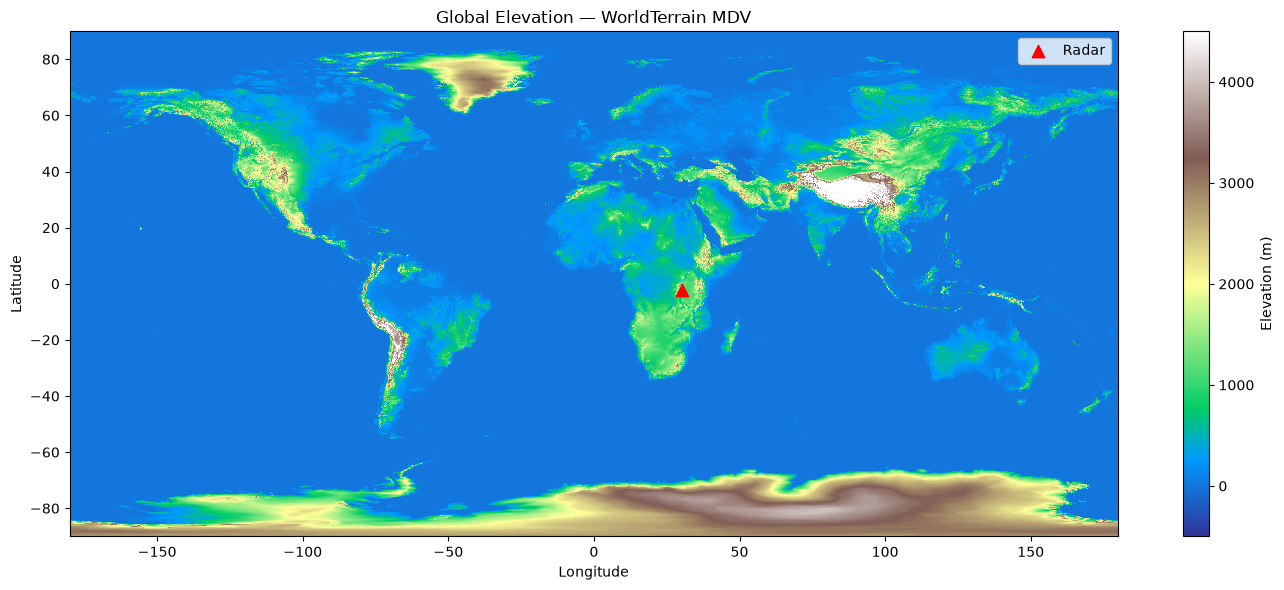

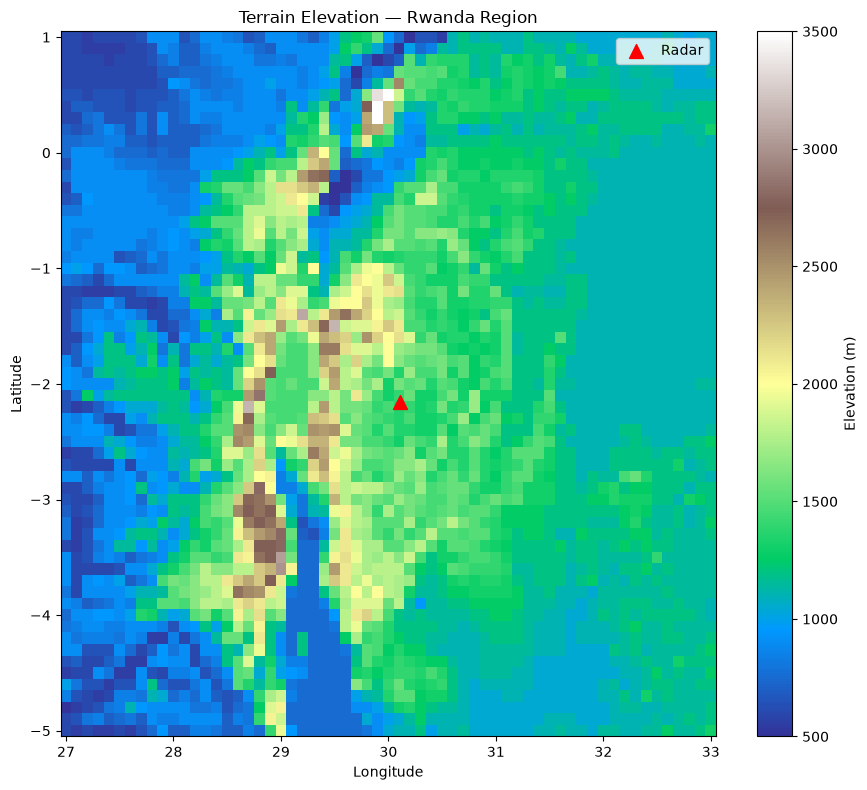

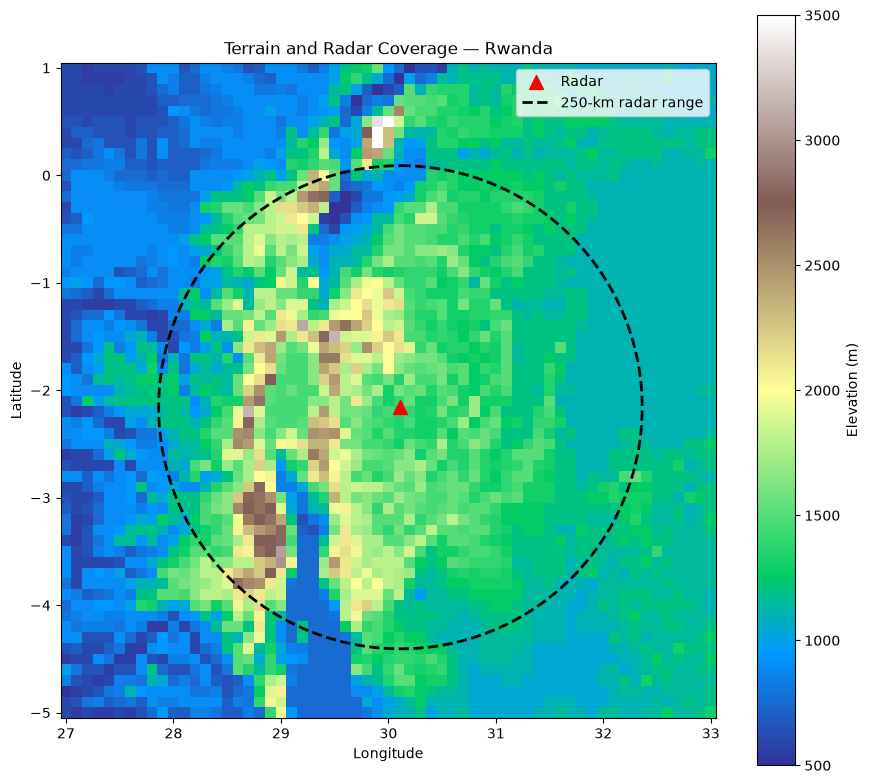

In [11]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from pathlib import Path

# ============================================================
# 1. LOAD DECODED TERRAIN
# ============================================================

TERRAIN_FILE = Path("/Volumes/Rain/world_terrain_decoded.npz")

data = np.load(TERRAIN_FILE)

terrain = data["elevation"].astype(float)

lon0 = float(data["lon0"])
lat0 = float(data["lat0"])
dx = float(data["dx"])
dy = float(data["dy"])

ny, nx = terrain.shape

lon = lon0 + np.arange(nx) * dx
lat = lat0 + np.arange(ny) * dy

# Radar location
RADAR_LAT = -2.158076
RADAR_LON = 30.112341
RADAR_ALT = 1616.0

# ============================================================
# 2. VALIDATE DATA
# ============================================================

print("=" * 60)
print("TERRAIN VALIDATION")
print("=" * 60)

print("Shape:", terrain.shape)
print("Minimum elevation:", np.nanmin(terrain))
print("Maximum elevation:", np.nanmax(terrain))
print("Valid fraction:", np.isfinite(terrain).mean())

iy = np.argmin(abs(lat - RADAR_LAT))
ix = np.argmin(abs(lon - RADAR_LON))

print("\nRadar elevation:", RADAR_ALT, "m")
print("DEM elevation near radar:", terrain[iy, ix], "m")
print("Difference:", terrain[iy, ix] - RADAR_ALT, "m")

print("\nRegional elevation statistics:")

region = (
    (lat >= -5) & (lat <= 1)
)

region_lon = (
    (lon >= 27) & (lon <= 33)
)

regional_terrain = terrain[
    np.ix_(region, region_lon)
]

print("Regional minimum:", np.nanmin(regional_terrain))
print("Regional maximum:", np.nanmax(regional_terrain))
print("Regional mean:", np.nanmean(regional_terrain))

# ============================================================
# 3. GLOBAL TERRAIN MAP
# ============================================================

fig, ax = plt.subplots(figsize=(14, 6))

im = ax.pcolormesh(
    lon,
    lat,
    terrain,
    cmap="terrain",
    shading="auto",
    vmin=-500,
    vmax=4500
)

ax.scatter(
    RADAR_LON,
    RADAR_LAT,
    color="red",
    marker="^",
    s=80,
    label="Radar"
)

ax.set_title("Global Elevation — WorldTerrain MDV")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()

plt.colorbar(
    im,
    ax=ax,
    label="Elevation (m)"
)

plt.tight_layout()
plt.show()

# ============================================================
# 4. REGIONAL TERRAIN MAP
# ============================================================

fig, ax = plt.subplots(figsize=(9, 8))

im = ax.pcolormesh(
    lon[region_lon],
    lat[region],
    regional_terrain,
    cmap="terrain",
    shading="auto",
    vmin=500,
    vmax=3500
)

ax.scatter(
    RADAR_LON,
    RADAR_LAT,
    color="red",
    marker="^",
    s=100,
    label="Radar",
    zorder=5
)

ax.set_title("Terrain Elevation — Rwanda Region")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()

plt.colorbar(
    im,
    ax=ax,
    label="Elevation (m)"
)

plt.tight_layout()
plt.show()

# ============================================================
# 5. RADAR COVERAGE MAP
# ============================================================

fig, ax = plt.subplots(figsize=(9, 8))

im = ax.pcolormesh(
    lon[region_lon],
    lat[region],
    regional_terrain,
    cmap="terrain",
    shading="auto",
    vmin=500,
    vmax=3500
)

ax.scatter(
    RADAR_LON,
    RADAR_LAT,
    color="red",
    marker="^",
    s=100,
    label="Radar",
    zorder=5
)

# Approximate 250-km radar coverage boundary
# Using a spherical Earth great-circle calculation.

radius_km = 250.0
earth_radius_km = 6371.0

bearings = np.linspace(0, 2 * np.pi, 361)

lat1 = np.radians(RADAR_LAT)
lon1 = np.radians(RADAR_LON)

angular_distance = radius_km / earth_radius_km

circle_lat = np.arcsin(
    np.sin(lat1) * np.cos(angular_distance)
    + np.cos(lat1) * np.sin(angular_distance)
    * np.cos(bearings)
)

circle_lon = lon1 + np.arctan2(
    np.sin(bearings)
    * np.sin(angular_distance)
    * np.cos(lat1),
    np.cos(angular_distance)
    - np.sin(lat1) * np.sin(circle_lat)
)

ax.plot(
    np.degrees(circle_lon),
    np.degrees(circle_lat),
    color="black",
    linewidth=2,
    linestyle="--",
    label="250-km radar range"
)

ax.set_title("Terrain and Radar Coverage — Rwanda")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
ax.legend()

plt.colorbar(
    im,
    ax=ax,
    label="Elevation (m)"
)

plt.tight_layout()
plt.show()
